# Lecture 16 notebook: the final portfolio

This notebook replays Lecture 16. The data are free and kept local, never committed: Lecture 14's 1990-2005 trend portfolio, Lecture 15's groups (extended back to 1985 for currencies), Shiller's S&P 500 data, FRED and OECD rates and yields, the central banks' 10-year yields and the capstone futures.

By default the notebook shows the shipped figure and results and checks the lecture's mechanics by hand. `RUN_ALL` also reruns the analysis into a separate folder (1,000 random strategies take a few minutes) and compares the key numbers. Recomputed results never overwrite the shipped ones.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings and data | |
| 1 | The key chart | §1 |
| 3 | The long currency build against Lecture 15's, by hand | §3 |
| 4 | Results, 1990-2005 and 2006-2022 | §4 |
| 5 | A 60/40 blend by hand | §5 |
| 6 | Costs | §6 |
| 7 | The realistic number by hand | §7 |
| 8 | Shipped against recomputed; a step of your own | |

## 0. Settings and data

In [1]:
import json, os, shutil, subprocess, sys, time
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display

HERE = Path.cwd(); SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
sys.path[:0] = [str(SCRIPTS)]
import l30_data as D, l29_combined as MC, l29_bonds_g10 as G, l29 as L
RUN_ALL = False                                                            # True: also rerun the analysis

SHIPPED = HERE / "results"; WORK = L.RAW / "l30_results"
if not WORK.exists(): shutil.copytree(SHIPPED, WORK)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
print("shipped results:", SHIPPED, "| recomputed results:", WORK)


def run(script, *args):
    t0 = time.time()
    env = {**os.environ, "PORTFOLIO_DATA": str(L.L28.L25.DATA), "L30_RESULTS": str(WORK), "L30_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, str(SCRIPTS / script), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode: print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script} {' '.join(args)}: {time.time() - t0:.0f} s")


def result(name, where=None):
    return json.loads(((where or WORK) / name).read_text(encoding="utf-8"))

shipped results: C:\Users\maxgn\New Trading Models\systematic-trading-notes\lectures\16-the-final-portfolio\results | recomputed results: C:\Users\maxgn\New Trading Models\data\raw\l30_results


## 1. The key chart

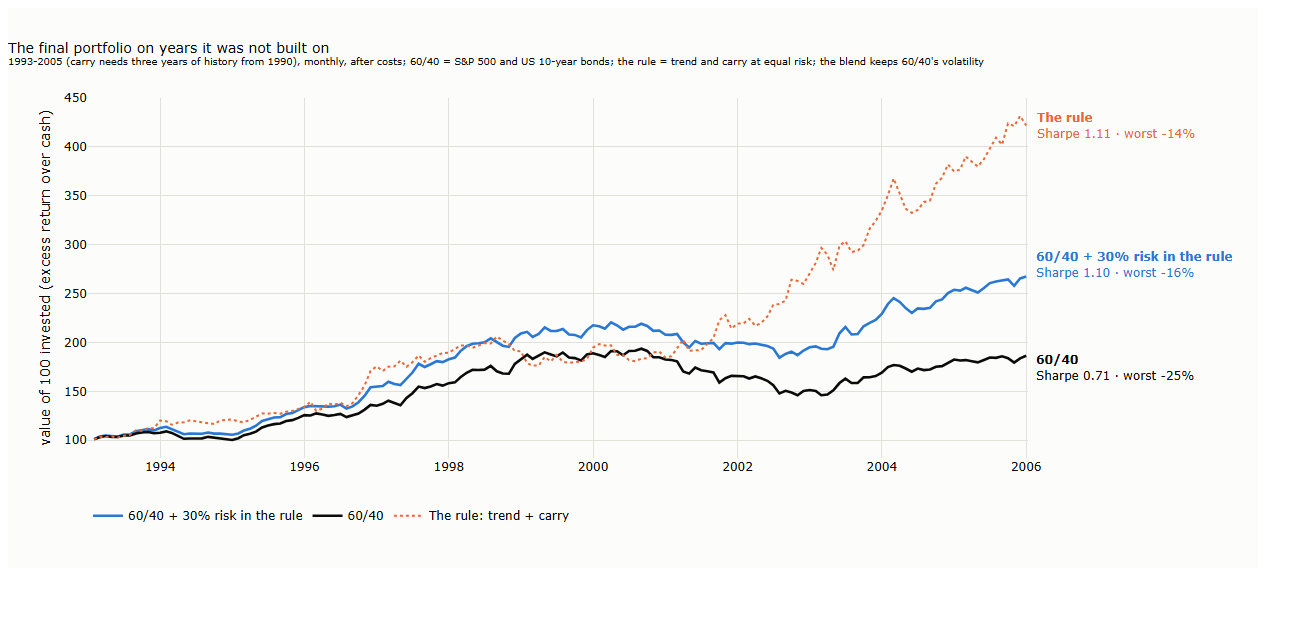

In [2]:
if RUN_ALL: run("l30_test.py", "1000"); run("l30_expect.py")
display(Image(filename=str(FIG / ("nb_30_key.png" if RUN_ALL else "30_key.png"))))

## 3. The long currency build, by hand

Currencies are rebuilt monthly from 1985 (the euro before 1999 through the German mark at 1.95583 marks per euro). Where they overlap, the monthly build should match Lecture 15's daily build compounded to months.

In [3]:
Rf, Cf, Sf = D.fx_monthly()
daily = MC.compound(L.FX.build()[1]).loc["2000-01":"2022-10"]
both = pd.concat([Rf, daily], axis=1, keys=["monthly", "daily"]).dropna()
print({c: round(both["monthly"][c].corr(both["daily"][c]), 3) for c in Rf})
print("euro before 1999, dollars per euro-equivalent, Dec 1998:", round(Sf["EUR"].loc["1998-12"], 4), "| Jan 1999 (the euro):", round(Sf["EUR"].loc["1999-01"], 4))

{'EUR': np.float64(1.0), 'JPY': np.float64(1.0), 'GBP': np.float64(1.0), 'CHF': np.float64(1.0), 'CAD': np.float64(1.0), 'AUD': np.float64(1.0), 'NZD': np.float64(1.0), 'NOK': np.float64(1.0), 'SEK': np.float64(1.0)}
euro before 1999, dollars per euro-equivalent, Dec 1998: 1.1713 | Jan 1999 (the euro): 1.1371


## 4. Results

In [4]:
T = result("test.json", SHIPPED)
rows = ["trend", "carry", "rule: trend + carry", "rival: + value", "US equities", "60/40"]
pd.DataFrame({pn: {k: f"{T[pn][k]['sharpe']:.2f} ({T[pn][k]['maxdd']:.0%})" for k in rows} for pn in ("1990-2005", "2006-2022")})

,1990-2005,2006-2022
trend,0.78 (-13%),0.67 (-19%)
carry,0.99 (-19%),0.54 (-21%)
rule: trend + carry,1.11 (-14%),0.84 (-19%)
rival: + value,0.89 (-10%),0.81 (-21%)
US equities,0.57 (-46%),0.56 (-51%)
60/40,0.71 (-25%),0.66 (-30%)


In [5]:
print("luck, 1990-2005:", {k: round(v, 2) for k, v in T["luck_1990_2005"].items()})
print("carry by group, 1990-2005:", {g: round(v, 2) for g, v in T["1990-2005"]["carry_groups"].items()}, "| first month trading:", T["1990-2005"]["groups_active"])

luck, 1990-2005: {'carry_beaten': 1.0, 'carry_median': -0.11, 'carry_p95': 0.36, 'rule_beaten': 1.0, 'rule_median': 0.51, 'rule_p95': 0.83}
carry by group, 1990-2005: {'fx': 0.74, 'commod': 0.05, 'bonds': 0.74, 'equity': -0.2} | first month trading: {'fx': '1990-01', 'commod': '2004-01', 'bonds': '1995-01', 'equity': '2001-01'}


## 5. A 60/40 blend by hand

60/40 with 30% of its risk budget moved to the rule: scale the rule to 60/40's volatility, take 70% of 60/40 and 30% of the scaled rule, and scale the blend back to 60/40's volatility.

In [6]:
LO = D.sixty_forty(); tr = D.trend_1990()
import l29_grids as GR
Gs = D.groups_long(); W = {g: GR.sig(Gs[g]["C"], Gs[g]["R"]) for g in Gs}
carry = MC.scale_total(pd.DataFrame({g: G.stream(W[g], Gs[g]["R"]) for g in Gs}).mean(axis=1, skipna=True)).loc["1990-01":"2005-12"]
X = pd.concat([tr.loc["1990-01":"2005-12"], carry], axis=1).dropna(); c = X.mean(axis=1); rule = (c * X.iloc[:, 0].std() / c.expanding(12).std().shift(1)).dropna()
s = LO["60/40"].reindex(rule.index); a = rule * s.std() / rule.std(); b = 0.7 * s + 0.3 * a; b = b * s.std() / b.std()
print(f"by hand: 60/40 {G.sharpe_m(s):.2f} -> with 30% {G.sharpe_m(b):.2f}; shipped {T['1990-2005']['investor']['0%']['sharpe']:.2f} -> {T['1990-2005']['investor']['30%']['sharpe']:.2f}")

by hand: 60/40 0.71 -> with 30% 1.10; shipped 0.71 -> 1.10


## 6. Costs

In [7]:
pd.DataFrame(T["costs"]).T.round(2)

,1990-2005,2006-2022
10 bp,1.01,0.68
20 bp,0.82,0.36


## 7. The realistic number by hand

Each period's backtest Sharpe ratio, times the ratio of trend's daily to monthly Sharpe ratio over the same months, with carry's costs at 10 bp; then the average across the three periods.

In [8]:
E = result("expect.json", SHIPPED)
r = E["rows"]; vals = [r["1990-2005"]["plus_costs_10bp"], r["2006-2022"]["plus_costs_10bp"], r["2013-2026"]["daily_equivalent"]]
print("daily / monthly ratios:", {k: round(v, 3) for k, v in E["daily_to_monthly"].items()})
print(f"by hand: average {np.mean(vals):.2f}, range {min(vals):.2f} to {max(vals):.2f}; shipped {E['average_after_haircuts']:.2f}")

daily / monthly ratios: {'1990-2005': 0.986, '2006-2022': 0.938}
by hand: average 0.69, range 0.43 to 1.00; shipped 0.69


## 8. Shipped against recomputed

With `RUN_ALL`, the rerun's key numbers against the shipped ones.

In [9]:
rows = [dict(number="1990-2005: trend + carry", shipped=result("test.json", SHIPPED)["1990-2005"]["rule: trend + carry"]["sharpe"], recomputed=result("test.json")["1990-2005"]["rule: trend + carry"]["sharpe"]),
        dict(number="realistic average", shipped=result("expect.json", SHIPPED)["average_after_haircuts"], recomputed=result("expect.json")["average_after_haircuts"])]
pd.DataFrame(rows).round(4)

,number,shipped,recomputed
0,1990-2005: trend + carry,1.1120,1.1120
1,realistic average,0.6902,0.6902


**A step of your own.** Pick one row of §8.1 of the lecture, write a dated plan for one addition to the fixed base layer, and judge it by what it adds to trend + carry on 1990-2005 and 2006-2022, counting it as a try.